# Facteur associes a la depression chez les etudiants
### Question : quels profils d‘etudiants sont les plus touches ?
### Etapes 1 : Preparer le dossier et charger les donnees

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/Student_Depression_DataSet.csv")
print(df.shape)
df.head(20)

(4464, 13)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
5,Female,24,Middle class,Single,Unmarried,Bachelor,9,3.80,Yes,Normal,17244,Chittagong,No
6,Female,21,Lower Middle class,Single,Unmarried,Family,9,3.50,Yes,Normal,1648,Dhaka,No
7,Female,19,Middle class,Single,Unmarried,Family,2,2.71,Yes,Abnormal,16782,Rajshahi,Yes
8,Female,21,Middle class,Single,Unmarried,Family,3,3.10,Yes,Abnormal,13386,Dhaka,Yes
9,Female,22,Middle class,In a Relationship,Married,Family,4,3.34,Yes,Normal,18131,Mymensingh,No


# Etapes 2 : Explorer (structure, types, valeurs)

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [3]:
print(df.isna().sum())
print("Doublons :", df.duplicated().sum())

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64
Doublons : 0


In [4]:
df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [5]:
for col in df.select_dtypes(include="object").columns:
    print(f"\n--- {col} –––")
    print(df[col].value_counts())


--- Gender –––
Gender
Female    2462
Male      2002
Name: count, dtype: int64

--- Family_background –––
Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

--- Relationship_status –––
Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

--- Marital_status –––
Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

--- Living_style –––
Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

--- friend_circle –––
friend_circle
Yes    3215
No     1249
Name: count, dtype: int64

--- Health_condition –––
Health_condition
Normal      1787
Good        1162
Abnormal     881
Critical     634
Name: count, dtype: int64

--- Home_division –––
Home_division
Dhaka         1527
Khulna         548
Rajshahi       488
Sylhet         445
Chittagong     400
Rangpur        363
Barisal        355
Mymensin

In [6]:
print(df["Depression"].value_counts(normalize=True).round(3) * 100)

Depression
No     73.1
Yes    26.9
Name: proportion, dtype: float64


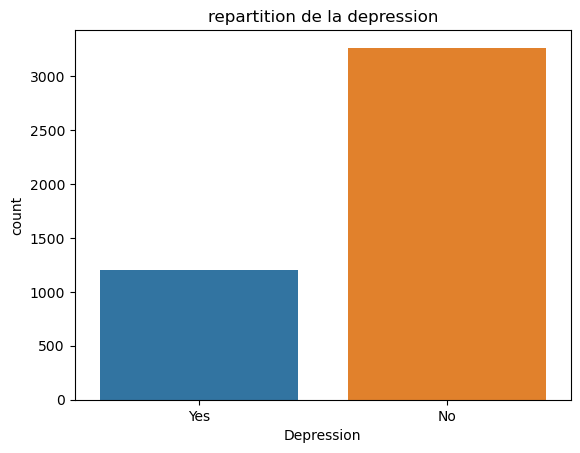

In [7]:
sns.countplot(data=df, x="Depression")
plt.title("repartition de la depression")
plt.show()

# Etapes 3: Nettoyer

In [8]:
df_clean = df.copy()

In [9]:
df_clean.columns = df_clean.columns.str.lower()
print(df_clean.columns.tolist())

['gender', 'age', 'family_background', 'relationship_status', 'marital_status', 'living_style', 'current_semester', 'cgpa', 'friend_circle', 'health_condition', 'cost_without_study', 'home_division', 'depression']


In [10]:
df_clean["depression_bin"] = df_clean["depression"].map({"Yes": 1, "No": 0})
print(df_clean["depression_bin"].mean().round(3) * 100 )

26.900000000000002


In [11]:
print("Semestre 0 :", (df_clean["current_semester"] == 0).sum())
print("cout a 0 :", (df_clean["cost_without_study"] == 0).sum())
print("18 ans ou moins et marie :", ((df_clean["age"] <= 18) & (df_clean["marital_status"] == "Married")).sum())

Semestre 0 : 42
cout a 0 : 2
18 ans ou moins et marie : 6


In [12]:
df_clean["suspect"] = ((df_clean["current_semester"] == 0) | (df_clean["cost_without_study"] == 0) | ((df_clean["age"] <= 18) & (df_clean["marital_status"] == "Married")))
print("Lignes suspect ", df_clean["suspect"].sum())

Lignes suspect  50


In [13]:
df_clean["age_group"] = pd.cut(df_clean["age"], bins=[16, 20, 22, 24, 28], labels=["17-20", "21-22", "23-24", "25-28"])
df_clean["cgpa_group"] = pd.cut(df_clean["cgpa"], bins=[0, 3.0, 3.5, 3.8, 4.0], labels=["<=3.0", "3.0-3.5", "3.5-3.8", ">3.8"])
print(df_clean["cgpa_group"].value_counts().sort_index())

cgpa_group
<=3.0       867
3.0-3.5    1529
3.5-3.8    1400
>3.8        668
Name: count, dtype: int64


In [14]:
df_clean.to_csv("data/student_depression_clean.csv", index=False)

### Etapes 04 l'analyse

In [15]:
df_clean[["depression_bin", "age_group", "cgpa_group"]].head()

,depression_bin,age_group,cgpa_group
0,1,21-22,3.0-3.5
1,1,17-20,3.5-3.8
2,1,23-24,3.0-3.5
3,0,17-20,3.5-3.8
4,1,21-22,>3.8


In [16]:
sns.set_theme(style="whitegrid")

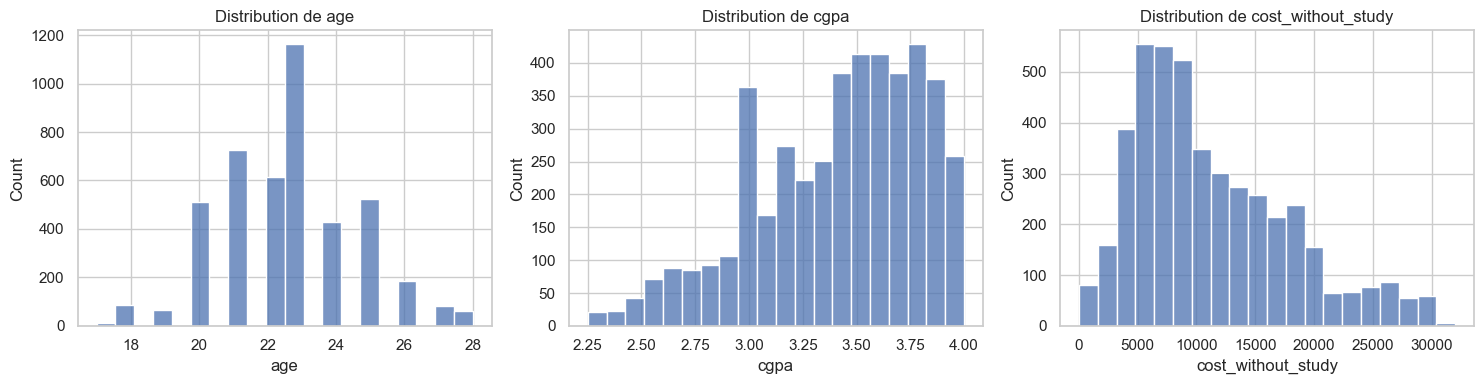

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "cgpa", "cost_without_study"]):
    sns.histplot(data= df_clean, x=col, bins=20 , ax=ax)
    ax.set_title(f"Distribution de {col}")
plt.tight_layout()
plt.show()

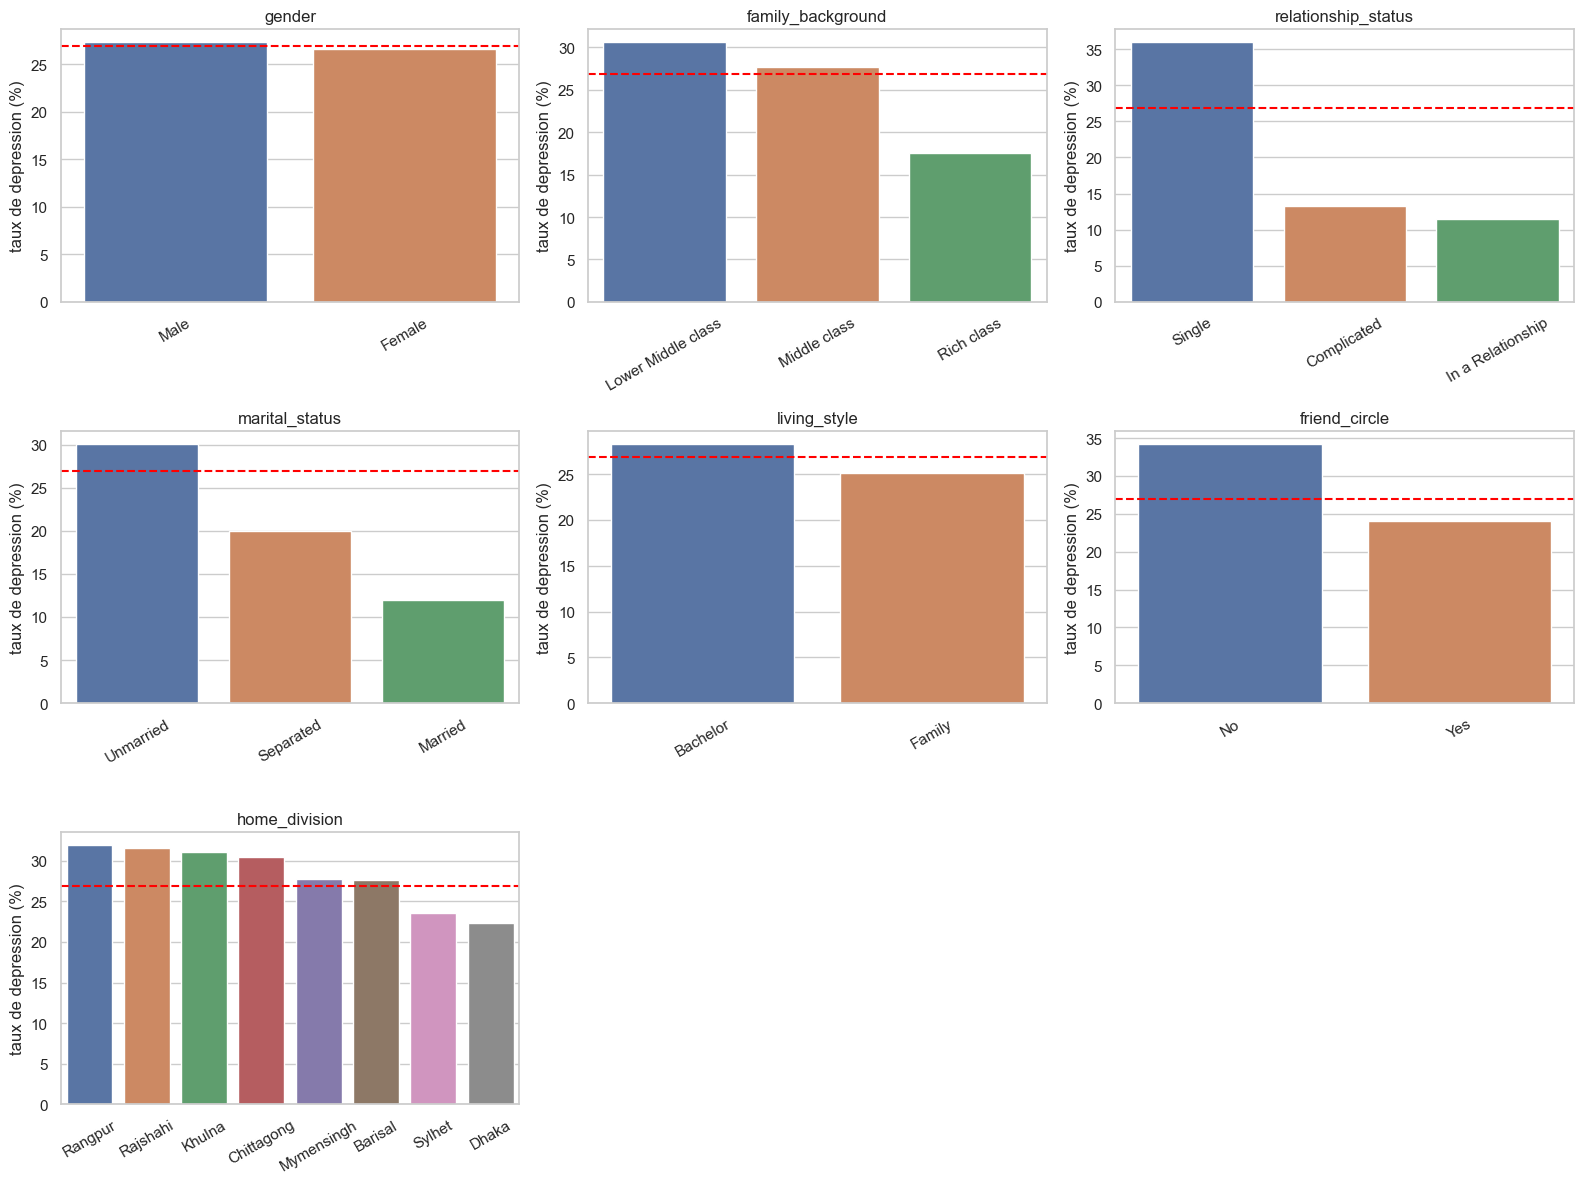

In [18]:
cats = ["gender", "family_background", "relationship_status", "marital_status", "living_style", "friend_circle", "home_division"]
taux_global = df_clean["depression_bin"].mean() * 100

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for ax, col in zip(axes, cats):
    taux = df_clean.groupby(col)["depression_bin"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=taux.index, y=taux.values, ax=ax)
    ax.axhline(taux_global, color="red", linestyle="dashed")
    ax.set_title(col)
    ax.set_ylabel("taux de depression (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
for ax in axes[len(cats):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Remarque: (1) tout d'abords les celibataires sont a environs 36% de depression, contre 11.5% pour ceux en couple . ecart qui est tres enorme
### (2) : les celibatiares, les etudiants sans cercle d'amis (34% contre 24%) et les 17-20 ans (33%). L'isolement social ressort comme un fil conducteur.
### (3) : les etuddiants en couples et mariés (environ 12%), ainsi que ceux d'un milieu aisé (18% contre 31% pour la classe moyenne inferieure).

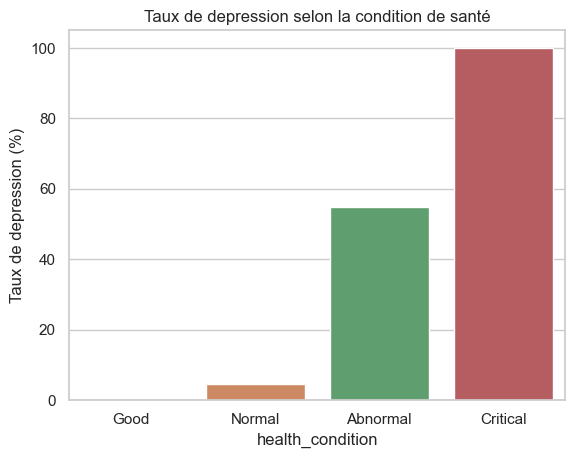

In [19]:
ordre = ["Good", "Normal", "Abnormal", "Critical"]
taux = df_clean.groupby("health_condition")["depression_bin"].mean().reindex(ordre) * 100
sns.barplot(x=taux.index, y=taux.values)
plt.title("Taux de depression selon la condition de santé")
plt.ylabel("Taux de depression (%)")
plt.show()

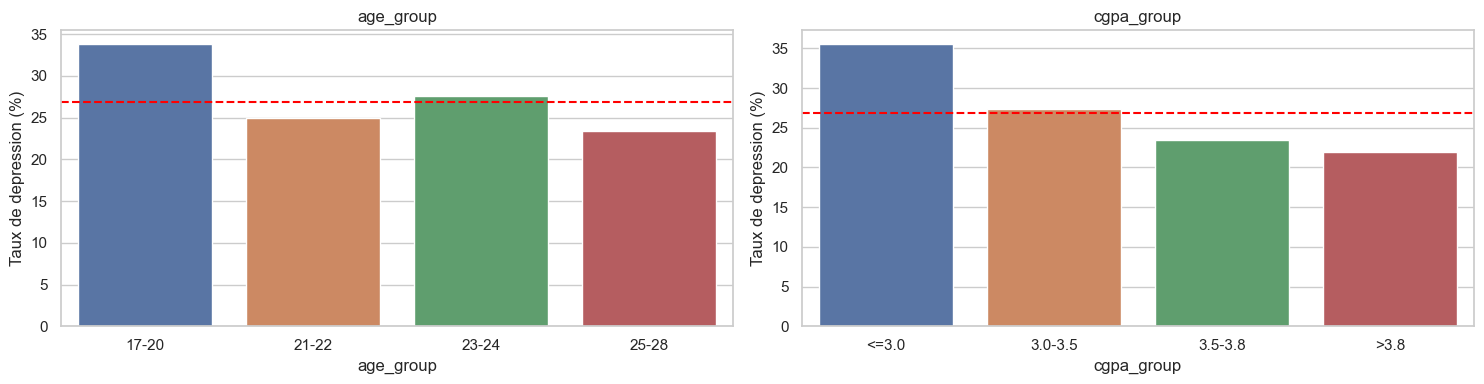

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, col in zip(axes, ["age_group", "cgpa_group"]):
    taux = df_clean.groupby(col, observed=True)["depression_bin"].mean() * 100
    sns.barplot(x=taux.index.astype(str), y=taux.values, ax=ax)
    ax.axhline(taux_global, color="red", linestyle="dashed")
    ax.set_title(col)
    ax.set_ylabel("Taux de depression (%)")
plt.tight_layout()
plt.show()

### Avec un CGPA de 3,0 ou moins, le taux est de 36%, contre  22% au dessus de 3,8. Le lien est reel mais moins fort que celui de la relation.

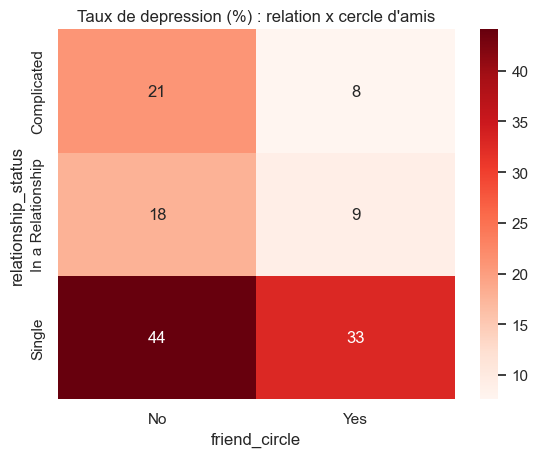

In [21]:
pivot = df_clean.pivot_table(values="depression_bin", index="relationship_status", columns="friend_circle", aggfunc="mean") * 100
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds")
plt.title("Taux de depression (%) : relation x cercle d'amis")
plt.show()

### Le genre n'a presque aucun effet (27% pour les homme contre pour les femmes).


### Etapes 05: Les tests statistiques.
 Les graphiques montrentdes ecarts, mais ils peuvent venir du hasards. j'utilise le test du chi2 (categorise) et le test de mann-whitney (nombred. un lienest significatif si p < 0,05, et le V de cramér mesure sa force (0 = aucun, 1 = parfait). 

In [22]:
from scipy import stats
cats = ["gender", "family_background", "relationship_status", "marital_status", "living_style", "friend_circle", "home_division", "health_condition"]
resultats = []
for col in cats:
    tableau = pd.crosstab(df_clean[col], df_clean["depression_bin"])
    chi2, p, dof, attendu = stats.chi2_contingency(tableau)
    n = tableau.values.sum()
    v = np.sqrt(chi2 / (n * (min(tableau.shape) - 1)))
    resultats.append({"variable": col, "p_value": p, "force_lien": round(v, 2)})
    
res = pd.DataFrame(resultats).sort_values("force_lien", ascending=False)
res["signification"] = res["p_value"] < 0.05
res

,variable,p_value,force_lien,signification
7,health_condition,0.000000e+00,0.81,True
2,relationship_status,1.725757e-68,0.26,True
3,marital_status,2.859241e-23,0.15,True
5,friend_circle,6.110981e-12,0.10,True
1,family_background,4.751088e-09,0.09,True
6,home_division,7.504653e-06,0.09,True
4,living_style,1.888030e-02,0.04,True
0,gender,6.406007e-01,0.01,False


### Variables categorielles 
Toutes les variables sont significatives sauf le genre (p ≃ 0,64). le statut de relation a le lienle plus fort (V ≃ 0,266), puis le statut marital (0,15) et le cercle d'amis (0,10). le milieu familiale, la region et le mode de vie ont des liens faibless (V < 0,1) : significatis grace a la taille de l'echantillon, maispeu importants en pratique. health_condition a un V de 0,81, anormalementeleve : cette variable est problablementlieé a la cible et je ne l'utilise pas pour expliquer la depression 

In [23]:
for col in ["age", "cgpa", "cost_without_study", "current_semester"]:
    oui = df_clean[df_clean["depression_bin"] == 1][col]
    non = df_clean[df_clean["depression_bin"] == 0][col]
    stat, p = stats.mannwhitneyu(oui, non)
    print(f"{col}: p = {p:.4f} | mediane depressifs = {oui.median()}, autres = {non.median()}")

age: p = 0.0092 | mediane depressifs = 23.0, autres = 23.0
cgpa: p = 0.0000 | mediane depressifs = 3.42, autres = 3.5
cost_without_study: p = 0.0209 | mediane depressifs = 10000.0, autres = 9300.0
current_semester: p = 0.2458 | mediane depressifs = 5.0, autres = 5.0


### Variables numeriques
Les notes (CGPA) different nettement : mediane de 3,42 chez les etudiants depressifs contre 3,50 chez les autres. L'age (p ≃ 0,009) et les depenses (p ≃ 0,02) sont significatifs, mais leurs medianes sont presque identiques,  donc l'effet est faible. Le semestre n'a aucun effet (p ≃ 0,25).

In [24]:
propres = df_clean[~df_clean["suspect"]]
comparaison = pd.DataFrame({
    "avec_tout": df_clean.groupby("relationship_status")["depression_bin"].mean(),
    "sans_suspect": propres.groupby("relationship_status")["depression_bin"].mean(),
}).round(3) * 100
comparaison

,avec_tout,sans_suspect
relationship_status,,
Complicated,13.2,13.5
In a Relationship,11.5,11.6
Single,35.9,36.0


### Robustesse 
50 lignes ont ete marquées comme suspectes. Sans elles, les taux changent de moins d'un point (celibataires : 35,9% contre 36,0%). Mes resultats ne dependent donc pas de ces cas.

### 6. Conclusions
### Ce que montrent les données
- **Le statut de relation est le facteur le plus lié à la dépression** : 36 % chez les célibataires contre 11,5 % chez les étudiants en couple (V de Cramér ≈ 0,26).
- **L'isolement social ressort** : 34 % de dépression chez les étudiants sans cercle d'amis, contre 24 % avec.
- **Les plus jeunes (17-20 ans) et les étudiants issus de milieux modestes** sont plus touchés (33 % et 31 %).
- **Les notes ont un lien modéré** : 36 % pour un CGPA de 3,0 ou moins, 22 % au-dessus de 3,8.
- **Le genre, le semestre et les dépenses n'ont pas d'effet clair.**

### Ce qui m'a surpris
La variable health_condition prédit presque parfaitement la dépression (0 % pour "Good", 100 % pour "Critical"). Un lien aussi parfait est irréaliste : elle est probablement construite à partir de la cible. Je l'ai exclue de mes conclusions.

### Limites
- Ce sont des **associations, pas des causes** : je ne peux pas dire que le célibat provoque la dépression.
- Les données viennent d'un **sondage au Bangladesh** (4 464 étudiants) : elles ne s'appliquent pas automatiquement à d'autres pays, dont le Cameroun.
- Je ne sais pas comment la dépression a été mesurée (auto-déclaration ? questionnaire ?). Le dataset peut aussi contenir des données simulées.
- Je n'ai que 12 variables : des facteurs importants (sommeil, stress, emploi du temps) manquent.
- Un échantillon n'est pas forcément représentatif de tous les étudiants.

### Recommandations
Si une université voulait cibler son soutien, les données suggèrent de porter une attention particulière aux **étudiants isolés, aux plus jeunes et à ceux dont les résultats sont faibles**. Cespistes sont des hypothèses à vérifier avec des spécialistes, pas des conclusions médicales.
